# RF + scratch-trained MLP ensemble

This implements the previously untested fixed blend: **25% Madrid RF + 25% Amsterdam RF + 50% scratch MLP**. The scratch network has random initial weights and is trained on exactly 25 Amsterdam labels/class. Madrid features fit its scaler; no Madrid labels train the neural network.

This executable experiment notebook uses the [training helper](../../scripts/rf_scratch_blend.py). Prerequisites: preprocessed city tables, baseline RF bundles/memberships and the saved Madrid-transfer experiment. Prepare dependencies with `uv sync --locked --extra deep-learning`. Default execution verifies and inspects saved artifacts; set `RETRAIN = True` to retrain all 15 scratch networks.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'pyproject.toml').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run Jupyter inside the repository.')
sys.path.insert(0, str(ROOT))
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts.rf_scratch_blend import OUT, CONFIG, METRICS, run, verify, train_scratch, predict_bundle
RETRAIN = False
if RETRAIN:
    run()
verify()

Verified 60 run scores, 311,904 probability rows, fixed weights, 15 label budgets and exported inference.


## Training implementation

All weights are initialized randomly. The architecture is 54 → 64 → 32 → 4, with ReLU and dropout 0.2. All layers train at learning rate 0.001 for 300 fixed epochs; outer labels never select epochs or settings. The five folds and three repetitions reuse exactly the baseline's 100-label samples. This experiment uses one neural seed per sample, not a five-network average.

In [2]:
print(CONFIG)
print(inspect.getsource(train_scratch))

{'seed': 42, 'hidden': [64, 32], 'dropout': 0.2, 'epochs': 300, 'learning_rate': 0.001, 'weight_decay': 0.01, 'rf_weight': 0.5, 'folds': 5, 'repetitions': 3, 'labels_per_class': 25, 'source_scaler_checkpoint_fold': 0}
def train_scratch(x, y, seed):
    """Random initialization; source weights and source labels are never used."""
    seed_all(seed)
    model = TransferMLP(x.shape[1])
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
    history = []
    for epoch in range(CONFIG['epochs']):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(model(x), y)
        assert torch.isfinite(loss)
        loss.backward()
        optimizer.step()
        history.append(dict(epoch=epoch+1, training_loss=loss.item()))
    model.eval()
    return model, history



## Matched comparison

Repetitions average within each fold first, then the five fold means are averaged. Fold SD describes variability and is not a confidence interval. The previous fine-tuned hybrid is the comparison to beat.

,macro_f1,weighted_f1,accuracy,balanced_accuracy,severe_error_rate,macro_f1_fold_sd,delta_vs_rf,delta_vs_fine_tuned_hybrid
method,,,,,,,,
rf_fine_tuned_blend,0.5679,0.5769,0.5767,0.5858,0.0953,0.0158,0.0185,0.0000
rf_scratch_blend,0.5664,0.5774,0.5772,0.5851,0.1013,0.0204,0.0170,-0.0015
scratch,0.5534,0.5634,0.5642,0.5760,0.1107,0.0199,0.0040,-0.0145
original_blend,0.5494,0.5636,0.5652,0.5559,0.0863,0.0258,0.0000,-0.0185


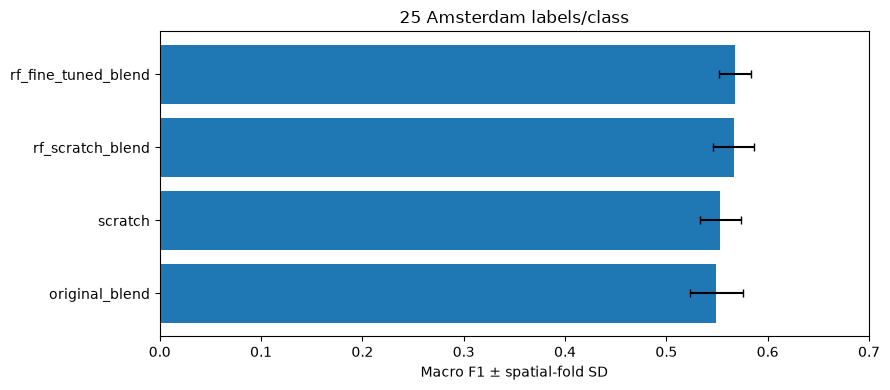

In [3]:
runs = pd.read_csv(OUT / 'run_metrics.csv')
folds = runs.groupby(['method', 'fold'])[METRICS].mean()
summary = pd.read_csv(OUT / 'summary.csv', index_col='method')
np.testing.assert_allclose(folds.groupby('method').mean(), summary[METRICS], atol=1e-12)
np.testing.assert_allclose(folds.groupby('method').macro_f1.std(), summary.macro_f1_fold_sd, atol=1e-12)
display(summary.sort_values('macro_f1', ascending=False).round(4))
ordered = summary.sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ordered.index, ordered.macro_f1, xerr=ordered.macro_f1_fold_sd, capsize=3)
ax.set(xlim=(0, .7), xlabel='Macro F1 ± spatial-fold SD', title='25 Amsterdam labels/class')
fig.tight_layout()
plt.show()

age_class,1,2,3,4
method,,,,
original_blend,0.6337,0.5872,0.4847,0.4919
rf_fine_tuned_blend,0.6514,0.5571,0.5437,0.5192
rf_scratch_blend,0.6467,0.5557,0.5596,0.5036
scratch,0.6387,0.5298,0.5533,0.4919


,fold,original_blend,rf_fine_tuned_blend,rf_scratch_blend,scratch,scratch_hybrid_minus_rf,scratch_hybrid_minus_fine_tuned_hybrid
0,0,0.53277,0.56070,0.56453,0.55079,0.03176,0.00382
1,1,0.56334,0.56336,0.56819,0.55628,0.00485,0.00483
2,2,0.55149,0.56196,0.57419,0.55810,0.02270,0.01223
3,3,0.58276,0.59583,0.59048,0.57857,0.00772,-0.00535
4,4,0.51657,0.55750,0.53456,0.52323,0.01799,-0.02295


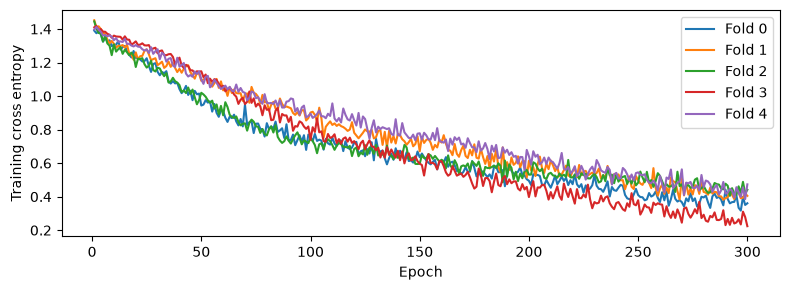

In [4]:
classes = pd.read_csv(OUT / 'class_metrics.csv')
display(classes.groupby(['method','fold','age_class']).f1.mean()
        .groupby(['method','age_class']).mean().unstack('age_class').round(4))
display(pd.read_csv(OUT / 'paired_fold_scores.csv').round(5))
history = pd.read_csv(OUT / 'training_history.csv')
fig, ax = plt.subplots(figsize=(8, 3))
for fold, frame in history.loc[history.repetition.eq(0)].groupby('fold'):
    ax.plot(frame.epoch, frame.training_loss, label=f'Fold {fold}')
ax.set(xlabel='Epoch', ylabel='Training cross entropy')
ax.legend()
fig.tight_layout()
plt.show()

## Load and predict with the exported example

This is a fold-0/repetition-0 demonstration, not a final production adaptation. It loads actual Madrid/Amsterdam RF pipelines, the source-fitted scaler and scratch-network weights. Prediction reads only the allowlisted feature columns. The example uses held-out fold-0 locations. All probability columns use class order 1–4.

In [5]:
target = pd.read_parquet(ROOT / 'data/preprocessed_age_labels/amsterdam_supervised_features.parquet')
example = target.loc[target.fold.eq(0)].head(8)
p = predict_bundle(OUT, example)
output = pd.DataFrame(dict(location_id=example.location_id.to_numpy(),
    predicted_age_class=np.arange(1,5)[p.argmax(1)],
    **{f'p{c}':p[:,i] for i,c in enumerate(range(1,5))}))
display(output)

,location_id,predicted_age_class,p1,p2,p3,p4
0,Amsterdam:20641:193600,4,0.033765,0.066719,0.391044,0.508471
1,Amsterdam:20641:193601,4,0.032859,0.106161,0.279916,0.581064
2,Amsterdam:20641:193603,4,0.039818,0.105793,0.371252,0.483137
3,Amsterdam:20642:193600,4,0.023966,0.029385,0.398429,0.548221
4,Amsterdam:20642:193602,4,0.041865,0.110360,0.326694,0.521081
5,Amsterdam:20642:193605,4,0.044358,0.107632,0.373550,0.474461
6,Amsterdam:20642:193606,4,0.048521,0.143730,0.330407,0.477341
7,Amsterdam:20642:193610,4,0.017616,0.085250,0.136319,0.760816


## Conclusion

The new scratch hybrid scores **0.5664 macro F1**, above RF alone (**0.5494**) but slightly below the fine-tuned hybrid (**0.5679**). Its severe-error rate is **10.13%**, versus **9.53%** for the fine-tuned hybrid and **8.63%** for RF.

Keep the fine-tuned hybrid as the current macro-F1 candidate. This small score difference does not establish statistical significance. All results use previously explored development folds, not an independent competition test. Multi-seed neural averaging remains untested.

See [the experiment report](../../docs/RF_SCRATCH_BLEND.md) and official [probability-voting guidance](https://scikit-learn.org/stable/modules/ensemble.html#voting-classifier). The installed scikit-learn skill informed the matched spatial splits, training-only preprocessing and class-aligned blending.